# WDPA data required to run the second half of this notebook is not included (too heavy). 
# There is no point in re-running WDPA code, as it takes time and results are already pre-saved. 
# Please see what this notebook does and go to eda_and_modelling.ipynb for main results :)
# ------------------------------------------------------------------------------

## Species Analysis

You are working for an NGO and are tasked with mapping biodiversity across the world. You have been provided with a dataset which encodes the geographic locations where different animal species have been observed. As part of the analyses into understanding what measures can be taken to help conservation efforts, there are a number of potential questions that one might consider, including:
- For any given species, where can one find them in the world?
- For a given location in the world, what and how many species may be observed there?
- Can you discover any interesting relationships between species? e.g. does the presence of one species in a location tell you about the possible presence of others?
- Can you discover any interesting relationships between species and locations? e.g. do specific species have a preference for certain habitats. 

Your goal is to take inspiration from the data analysis and machine learning algorithms we have seen in the class to create predictive models to explore questions such as, but not limited to, the ones above. The data has been processed for you in terms of train and test files already, including some additional training data if you would like to use it. Note, you should not train on the test data. A simple script that details how to load and minimally visualise this data is also included. 

Data sources:
 -  train data is from iNaturalist -  www.inaturalist.org
 -  test data is IUCN - https://www.iucnredlist.org/resources/spatial-data-download

You can find out information about each species by appending the taxon_id to this URL, e.g. for 22956: 'Leptodactylus mystacinus', the URL is: 
https://www.inaturalist.org/taxa/22956. 
Note some species might not be on the website anymore

Things to keep in mind: 
 - data has been collected by citizen scientists so it is noisy

Possible questions to explore: 
 - train a separate model to predict what locations a species of interest is present 
 - train a single model instead of per species model 
 - how to deal with "positive only data"
 - dealing with noisy/biased training data
 - using other input features e.g. climate data from  WorldClim Bioclimatic 
   variables  https://www.worldclim.org/data/worldclim21.html
 - how to evaluate e.g. what is a good metric to use?

## Imports and path

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import warnings
from tqdm import tqdm
from shapely.geometry import Point
import osmnx as ox
import srtm
import fiona
import contextlib
import io
import csv

In [2]:
path = '../data/'

## Code from explore_species_data.py

In [16]:
# loading training data    
data_train = np.load(path + 'species_train.npz')
train_locs = data_train['train_locs']  # 2D array, rows are number of datapoints and columns are "latitude" and "longitude"
train_ids = data_train['train_ids']    # 1D array, entries are the ID of the species that is present at the corresponding location in train_locs
species = data_train['taxon_ids']      # list of species IDe. Note these do not necessarily start at 0 (or 1)

species_names = dict(zip(data_train['taxon_ids'], data_train['taxon_names']))  # latin names of species 

# loading test data 
data_test = np.load(path + 'species_test.npz', allow_pickle=True)
test_locs = data_test['test_locs']    # 2D array, rows are number of datapoints and columns are "latitude" and "longitude"
test_pos_inds = dict(zip(data_test['taxon_ids'], data_test['test_pos_inds'])) # data_test['test_pos_inds'] is a list of lists that contain the indices in test_locs where a given species is present

In [17]:
# data stats
print('Train Stats:')
print('Number of species in train set:           ', len(species))
print('Number of train locations:                ', train_locs.shape[0])

_, species_counts = np.unique(train_ids, return_counts=True)
print('Average number of locations per species:  ', species_counts.mean())
print('Minimum number of locations for a species:', species_counts.min())
print('Maximum number of locations for a species:', species_counts.max())

Train Stats:
Number of species in train set:            500
Number of train locations:                 272037
Average number of locations per species:   544.074
Minimum number of locations for a species: 50
Maximum number of locations for a species: 2000



Displaying random species:
4805 - Charadrius tricollaris


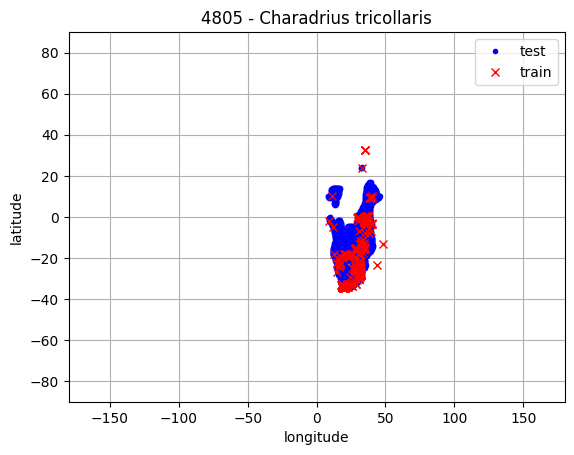

In [18]:
# plot train and test data for a random species
plt.close('all')
plt.figure(0)

sp = np.random.choice(species)
print('\nDisplaying random species:')
print(str(sp) + ' - ' + species_names[sp]) 

# get test locations and plot
# test_inds_pos is the locations where the selected species is present
# test_inds_neg is the locations where the selected species is not present
test_inds_pos = test_pos_inds[sp]  
test_inds_neg = np.setdiff1d(np.arange(test_locs.shape[0]), test_pos_inds[sp])
plt.plot(test_locs[test_inds_pos, 1], test_locs[test_inds_pos, 0], 'b.', label='test')

# get train locations and plot
train_inds_pos = np.where(train_ids == sp)[0]
plt.plot(train_locs[train_inds_pos, 1], train_locs[train_inds_pos, 0], 'rx', label='train')

plt.title(str(sp) + ' - ' + species_names[sp])
plt.grid(True)
plt.xlim([-180, 180])
plt.ylim([-90, 90])
plt.ylabel('latitude')
plt.xlabel('longitude')
plt.legend()
plt.show()

## Simple Gaussian Naive Bayes model

In [28]:
from sklearn.utils import resample
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix

In [ ]:
cum_mat = [[0.0, 0.0], [0.0, 0.0]]
cum_count = 0

# training Naive Bayes model for species distribution prediction
for a_id in species_names.keys(): 

    # quick manual prep with rough names
    a_hit = (train_ids == a_id)
    b_hit = ~a_hit
    a_loc = train_locs[a_hit]
    b_loc = train_locs[b_hit]
    a_tag = np.ones(len(a_loc))
    b_tag = np.zeros(len(b_loc))

    # crude balance so negatives do not swamp positives
    if len(a_loc) > 0 and len(b_loc) > 0:
        keep_n = min(len(a_loc), len(b_loc))
        b_loc = resample(b_loc, n_samples=keep_n, replace=False, random_state=9)
        b_tag = np.zeros(len(b_loc))

    x_train = np.vstack([a_loc, b_loc])
    y_train = np.hstack([a_tag, b_tag])
    shuffle_ids = np.random.permutation(len(x_train))
    x_train = x_train[shuffle_ids]
    y_train = y_train[shuffle_ids]

    # building test split
    c_pos = test_pos_inds.get(a_id, [])
    c_neg = np.setdiff1d(np.arange(len(test_locs)), c_pos)
    x_test = np.vstack([test_locs[c_pos], test_locs[c_neg]])
    y_test = np.hstack([np.ones(len(c_pos)), np.zeros(len(c_neg))])

    # training Gaussian Naive Bayes, predict and report the result
    nb = GaussianNB()
    nb.fit(x_train, y_train)

    zz = nb.predict(x_test)
    zz_p = nb.predict_proba(x_test)[:, 1]

    mat = confusion_matrix(y_test, zz, normalize='true')
    # mat_n = mat / mat.sum(axis=1, keepdims=True)

    cum_mat += mat
    cum_count += 1

print(cum_mat / cum_count)

# [[0.97728387 0.02271613]
#  [0.1605717  0.8394283 ]]

[[0.97728387 0.02271613]
 [0.1605717  0.8394283 ]]


## Transforming data into DataFrames

In [ ]:
data = np.load(path + 'species_train.npz', allow_pickle=True)

print("Keys in the file:", data.files)

for key in data.files:
    print()
    print("Key:", key)
    print("Shape:", data[key].shape)
    print("Data type:", data[key].dtype)
    print("First few elements:\n", data[key][:5])

Keys in the file: ['train_locs', 'train_ids', 'taxon_ids', 'taxon_names']

Key: train_locs
Shape: (272037, 2)
Data type: float32
First few elements:
 [[-18.286728 143.48125 ]
 [-13.099798 130.78365 ]
 [-13.965274 131.69514 ]
 [-12.85395  132.8005  ]
 [-12.19679  134.27933 ]]

Key: train_ids
Shape: (272037,)
Data type: int32
First few elements:
 [31529 31529 31529 31529 31529]

Key: taxon_ids
Shape: (500,)
Data type: int64
First few elements:
 [ 31529   3117 116872  13392  13456]

Key: taxon_names
Shape: (500,)
Data type: <U31
First few elements:
 ['Lophognathus gilberti' 'Patagioenas flavirostris'
 'Cincloramphus cruralis' 'Dicaeum agile' 'Orthonyx temminckii']


In [132]:
data = np.load(path + 'species_train.npz')

train_locs = data['train_locs']        # (272037, 2)
train_ids = data['train_ids']          # (272037,)
taxon_ids = data['taxon_ids']          # (500,)
taxon_names = data['taxon_names']      # (500,)

species_lookup = pd.DataFrame({
    'taxon_id': taxon_ids,
    'taxon_name': taxon_names
})

print(species_lookup)

train_df = pd.DataFrame({
    'latitude': train_locs[:, 0],
    'longitude': train_locs[:, 1],
    'taxon_id': train_ids
})

print(train_df)

     taxon_id                taxon_name
0       31529     Lophognathus gilberti
1        3117  Patagioenas flavirostris
2      116872    Cincloramphus cruralis
3       13392             Dicaeum agile
4       13456       Orthonyx temminckii
..        ...                       ...
495     10585   Calamospiza melanocorys
496    225741         Neotamias canipes
497     10168       Pooecetes gramineus
498    116950          Lybius torquatus
499    145031       Copsychus fulicatus

[500 rows x 2 columns]
         latitude   longitude  taxon_id
0      -18.286728  143.481247     31529
1      -13.099798  130.783646     31529
2      -13.965274  131.695145     31529
3      -12.853950  132.800507     31529
4      -12.196790  134.279327     31529
...           ...         ...       ...
272032  33.716885   73.203621    145031
272033  24.600239   72.730560    145031
272034  18.849600   80.654129    145031
272035  21.073837   75.945656    145031
272036  18.142048   73.791260    145031

[272037 rows x 

In [ ]:
data = np.load(path + 'species_test.npz', allow_pickle=True)

print("Keys in the file:", data.files)

for key in data.files:
    if key != 'allow_pickle':
        print()
        print("Key:", key)
        print("Shape:", data[key].shape)
        print("Data type:", data[key].dtype)
        print("First few elements:\n", data[key][:5])

Keys in the file: ['test_locs', 'test_pos_inds', 'taxon_ids', 'taxon_names', 'allow_pickle']

Key: test_locs
Shape: (288122, 2)
Data type: float32
First few elements:
 [[   9.630478  -173.5356   ]
 [   3.8393748 -162.54446  ]
 [   4.2891693 -167.94478  ]
 [   3.8798492 -169.72046  ]
 [  -6.2372103 -169.55412  ]]

Key: test_pos_inds
Shape: (500,)
Data type: object
First few elements:
 [list([112332, 113373, 113479, 113519, 113980, 146863, 146868, 146869, 146870, 146874, 146876, 146877, 146881, 146884, 146886, 146898, 146904, 146908, 146922, 146939, 146943, 146946, 146951, 146953, 146960, 146969, 146970, 146975, 146982, 146987, 146997, 147004, 147015, 147020, 147026, 147031, 147036, 147044, 147048, 147050, 147054, 147056, 147057, 147062, 147065, 147071, 147072, 147077, 147078, 147079, 147086, 147096, 147103, 147107, 147111, 147112, 147123, 147134, 147135, 147138, 147139, 147144, 147148, 147152, 147153, 147160, 147164, 147166, 147167, 147173, 147181, 147186, 147190, 147197, 147202, 147204

In [134]:
data = np.load(path + 'species_test.npz', allow_pickle=True)

test_locs = data['test_locs']          # (288122, 2)
test_pos_inds = data['test_pos_inds']  # (500,)
taxon_ids = data['taxon_ids']          # (500,)
taxon_names = data['taxon_names']      # (500,)

test_df = pd.DataFrame(test_locs, columns=['latitude', 'longitude'])

# building list of all triples (lat, lon, species)
records = []

for species_id, inds in zip(taxon_ids, test_pos_inds):
    locs = test_df.iloc[inds]
    temp = locs.assign(taxon_id=species_id)
    records.append(temp)

test_df = pd.concat(records, ignore_index=True)

print(test_df)

          latitude   longitude  taxon_id
0       -19.884237  126.052979     31529
1       -20.219316  124.723953     31529
2       -20.053690  125.386505     31529
3       -19.973000  126.462440     31529
4       -19.962839  124.980362     31529
...            ...         ...       ...
1706641  31.998211   72.541458    145031
1706642  26.927755   69.225052    145031
1706643  23.349318   70.605515    145031
1706644  23.706282   68.259659    145031
1706645  24.304489   70.202431    145031

[1706646 rows x 3 columns]


In [ ]:
# species_lookup = species_lookup.drop('Unnamed: 0', axis=1)
# train_df = train_df.drop('Unnamed: 0', axis=1)
# test_df = test_df.drop('Unnamed: 0', axis=1)

species_lookup.to_csv(path + 'species_lookup.csv', index=False)
print(species_lookup.shape)
train_df.to_csv(path + 'train_df.csv', index=False)
print(train_df.shape)
test_df.to_csv(path + 'test_df.csv', index=False)
print(test_df.shape)

(500, 2)
(272037, 3)
(1706646, 3)


## Getting WDPA dataset

In [ ]:
# wdpa1 = gpd.read_file(path + "WDPA_dataset/WDPA_part_1/WDPA_Oct2025_Public_shp-polygons.shp")
# wdpa2 = gpd.read_file(path + "WDPA_dataset/WDPA_part_2/WDPA_Oct2025_Public_shp-polygons.shp")
# wdpa = gpd.GeoDataFrame(pd.concat([wdpa1, wdpa2], ignore_index=True), crs=wdpa1.crs)
# wdpa = wdpa.to_crs("EPSG:4326")  # ensure lat/lon
# wdpa.to_file(path + "WDPA_all.gpkg", driver="GPKG")

In [ ]:
wdpa = gpd.read_file(path + "WDPA_all.gpkg", layer="WDPA_Global")

In [17]:
wdpa.shape

(195778, 31)

In [59]:
max_values=10

for col in wdpa.columns:
    if wdpa[col].dtype != 'geometry':  # skip geometry column
        unique_vals = wdpa[col].dropna().unique()  # remove NaNs
        print(col + ":" + str(list(unique_vals[:max_values])))  # take up to 10 values

WDPAID:[391154.0, 391155.0, 391156.0, 391158.0, 391159.0, 391160.0, 391161.0, 391162.0, 391165.0, 391166.0]
WDPA_PID:['391154', '391155', '391156', '391158', '391159', '391160', '391161', '391162', '391165', '391166']
PA_DEF:['1']
NAME:['2025090 Biotopskydd 2010:329', '2025506 Skuteskär', '2024120 Biotopskydd 2010:216', '2025790 Storön', '2014809 Näverheden', '2024118 Biotopskydd 2010:194', '2014787 Biotopskydd 2009:227', '2023763 Biotopskydd 2010:88', '2025916 Biotopskydd 2010:293', '2024549 Biotopskydd 2010:304']
ORIG_NAME:['2025090 Biotopskydd 2010:329', '2025506 Skuteskär', '2024120 Biotopskydd 2010:216', '2025790 Storön', '2014809 Näverheden', '2024118 Biotopskydd 2010:194', '2014787 Biotopskydd 2009:227', '2023763 Biotopskydd 2010:88', '2025916 Biotopskydd 2010:293', '2024549 Biotopskydd 2010:304']
DESIG:['Biotopskyddsområde', 'Djur- och växtskyddsområde', 'Naturreservat', 'Övriga', 'Naturvårdsområde', 'Réserve naturelle nationale', 'Arrêté de protection de biotope', 'Réserve bio

WDPA columns: 
WDPAID, WDPA_PID, PA_DEF, NAME, ORIG_NAME, DESIG, DESIG_ENG, DESIG_TYPE, IUCN_CAT, INT_CRIT, MARINE, REP_M_AREA, GIS_M_AREA, REP_AREA, GIS_AREA, NO_TAKE, NO_TK_AREA, STATUS, STATUS_YR, GOV_TYPE, OWN_TYPE, MANG_AUTH, MANG_PLAN, VERIF, METADATAID, SUB_LOC, PARENT_ISO, ISO3, SUPP_INFO, CONS_OBJ, geometry

See WDPA_documentation for what these mean. 

In [141]:
wdpa

,WDPAID,WDPA_PID,PA_DEF,NAME,ORIG_NAME,DESIG,DESIG_ENG,DESIG_TYPE,IUCN_CAT,INT_CRIT,...,MANG_AUTH,MANG_PLAN,VERIF,METADATAID,SUB_LOC,PARENT_ISO,ISO3,SUPP_INFO,CONS_OBJ,geometry
0,391154.0,391154,1,2025090 Biotopskydd 2010:329,2025090 Biotopskydd 2010:329,Biotopskyddsområde,Habitat Protection Area,National,Ia,Not Applicable,...,County Administrative Board and Regional Board...,Not Reported,State Verified,2013,Not Reported,SWE,SWE,Not Applicable,Not Applicable,"POLYGON ((18.71153 57.62068, 18.71141 57.62147..."
1,391155.0,391155,1,2025506 Skuteskär,2025506 Skuteskär,Djur- och växtskyddsområde,Wildlife and Plant Sanctuary,National,Not Assigned,Not Applicable,...,County Administrative Board and Local Authorities,Not Reported,State Verified,2013,Not Reported,SWE,SWE,Not Applicable,Not Applicable,"POLYGON ((11.49114 57.92335, 11.49118 57.92335..."
2,391156.0,391156,1,2024120 Biotopskydd 2010:216,2024120 Biotopskydd 2010:216,Biotopskyddsområde,Habitat Protection Area,National,Ia,Not Applicable,...,County Administrative Board and Regional Board...,Not Reported,State Verified,2013,Not Reported,SWE,SWE,Not Applicable,Not Applicable,"POLYGON ((16.90628 61.89431, 16.90553 61.89474..."
3,391158.0,391158,1,2025790 Storön,2025790 Storön,Djur- och växtskyddsområde,Wildlife and Plant Sanctuary,National,Not Assigned,Not Applicable,...,County Administrative Board and Local Authorities,Not Reported,State Verified,2013,Not Reported,SWE,SWE,Not Applicable,Not Applicable,"POLYGON ((12.24480 59.01100, 12.24477 59.01095..."
4,391159.0,391159,1,2014809 Näverheden,2014809 Näverheden,Naturreservat,Nature Reserve,National,Ia,Not Applicable,...,County Administrative Board and Local Authorities,Not Reported,State Verified,2013,Not Reported,SWE,SWE,Not Applicable,Not Applicable,"POLYGON ((14.60178 61.76166, 14.60253 61.76316..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195773,555791421.0,555791421,1,El Chorlo,El Chorlo,Reserva Natural de la Sociedad Civil,Civil Society Nature Reserve,National,VI,Not Applicable,...,Parques Nacionales Naturales de Colombia,https://runap.parquesnacionales.gov.co/area-pr...,State Verified,1861,Not Reported,COL,COL,Not Applicable,Not Applicable,"POLYGON ((-75.64914 4.08850, -75.64911 4.08848..."
195774,555791422.0,555791422,1,La Esperanza,La Esperanza,Reserva Natural de la Sociedad Civil,Civil Society Nature Reserve,National,VI,Not Applicable,...,Parques Nacionales Naturales de Colombia,https://runap.parquesnacionales.gov.co/area-pr...,State Verified,1861,Not Reported,COL,COL,Not Applicable,Not Applicable,"POLYGON ((-75.71779 1.40098, -75.71781 1.40089..."
195775,555794924.0,555794924,1,Ausangate,Ausangate,Área de Conservación Privada,Private Conservation Area,National,Not Reported,Not Applicable,...,Comunidad Nativa de Ausangate,Not Reported,State Verified,1811,PE-CUS,PER,PER,Not Applicable,Not Applicable,"POLYGON ((-71.32540 -13.67703, -71.32493 -13.6..."
195776,555794925.0,555794925,1,San Pedro de Chonta,San Pedro de Chonta,Área de Conservación Regional,Regional Conservation Area,National,Not Reported,Not Applicable,...,Gobierno Regional de Huánuco,Not Reported,State Verified,1811,PE-HUA,PER,PER,Not Applicable,Not Applicable,"POLYGON ((-77.11751 -8.47911, -77.11654 -8.479..."


In [ ]:
wdpa.to_parquet(path + "wdpa.parquet")
# wdpa = gpd.read_parquet(path + "wdpa.parquet")

## Joining the dataset with preservation areas (only training file is used here)

In [102]:
df = train_df

df = df[df['latitude'].between(-90, 90) & df['longitude'].between(-180, 180)]
gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326")

print("Number of rows that occur more than once:")
print(gdf.value_counts().value_counts().sort_index())
print()
print("Rows that occur more than once:")
print(gdf[gdf.duplicated(keep=False)].sort_index())
print()
print("Full GeoDataFrame:")
print(gdf)

Number of rows that occur 1, 2, 3, ... times:
count
1      243517
2        5884
3        1515
4         595
5         315
6         169
7         112
8          64
9          47
10         41
11         25
12         23
13         17
14         12
15         15
16          8
17         12
18          9
19         12
20          2
21          9
22          3
23          5
24          2
25          8
26          2
27          4
28          2
29          1
30          1
31          3
34          3
38          3
41          1
43          3
48          1
49          1
52          1
56          1
59          1
60          1
61          1
67          1
73          1
74          1
77          1
85          1
88          1
89          1
90          1
108         1
133         1
155         1
174         1
212         1
Name: count, dtype: int64

Rows that occur more than once:
         latitude   longitude  taxon_id                     geometry
10     -13.135027  132.525543     31529  POINT (13

In [ ]:
warnings.simplefilter(action='ignore', category=FutureWarning)

n_chunks = 2721

chunks = np.array_split(gdf, n_chunks)

results = []

# for chunk in tqdm(chunks, total=n_chunks, desc="Processing chunks"):

for i, chunk in enumerate(chunks):
    print(f"Processing chunk {i+1}/{n_chunks} with {len(chunk)} points")

    joined = gpd.sjoin(chunk, wdpa, how="left", predicate="within")

    results.append(joined)

    if i == 0: 
        joined.to_csv(path + 'species_train_annotated.csv', index=False)
    else: 
        joined.to_csv(path + 'species_train_annotated.csv', mode='a', index=False, header=False)

gdf_joined = pd.concat(results, ignore_index=True)

print("Spatial join complete!")

gdf = gdf.to_crs(wdpa.crs)

# spatial join: how="left" keeps all points, predicate="within" finds polygons that contain the points
gdf_joined = gpd.sjoin(gdf, wdpa, how="left", predicate="within")

In [ ]:
print(f"Rows not matched to preservation area: {gdf_joined['index_right'].isna().sum()} out of {gdf.shape[0]}")

# group by lat/lon and count how many distinct WDPA_PID values each point has
multi_hits = (
    gdf_joined.groupby(["latitude", "longitude"])["WDPA_PID"]
    .nunique()
    .reset_index(name="num_protected_areas")
)

multi_hits = multi_hits[multi_hits["num_protected_areas"] > 1]
print("Number of points belonging to multiple protected areas:", len(multi_hits))

# join back to the full data to see which polygons each point belongs to
duplicates = gdf_joined.merge(
    multi_hits[["latitude", "longitude"]],
    on=["latitude", "longitude"],
    how="inner"
).sort_index()

print("Points belonging to multiple protected areas:")
print(duplicates)

Rows not matched to preservation area: 226866 out of 272037
Number of points belonging to multiple protected areas: 8901
Points belonging to multiple protected areas:


,latitude,longitude,taxon_id,geometry,index_right,WDPAID,WDPA_PID,PA_DEF,NAME,ORIG_NAME,...,OWN_TYPE,MANG_AUTH,MANG_PLAN,VERIF,METADATAID,SUB_LOC,PARENT_ISO,ISO3,SUPP_INFO,CONS_OBJ
0,21.492943,-106.449142,3117,POINT (-106.44914 21.49294),6910.0,902481.0,902481,1,Islands and Protected Areas of the Gulf of Cal...,Islas y Áreas Protegidas del Golfo de California,...,Not Reported,Ministry of the Environment and Natural Resour...,Not Reported,State Verified,946.0,MX-BCN;MX-BCS;MX-SON;MX-SIN;MX-NAY,MEX,MEX,Not Applicable,Not Applicable
1,21.492943,-106.449142,3117,POINT (-106.44914 21.49294),43562.0,555547569.0,555547569,1,Islas Marías,Islas Marías,...,Not Reported,Ministry of the Environment and Natural Resour...,Not Reported,State Verified,1850.0,MX-NAY,MEX,MEX,Not Applicable,Not Applicable
2,11.481284,-85.559021,3117,POINT (-85.55902 11.48128),43565.0,555547572.0,555547572,1,Reserva de Biosfera Isla de Ometepe,Reserva de Biosfera Isla de Ometepe,...,Not Reported,Ministerio del Ambiente y Los Recursos Natural...,Not Reported,State Verified,820.0,NI-SJ,NIC,NIC,Not Applicable,Not Applicable
3,11.481284,-85.559021,3117,POINT (-85.55902 11.48128),136430.0,555698174.0,555698174,1,Humedal Istiam Peña Inculca,Humedal Istiam Peña Inculca,...,Not Reported,Ministerio del Ambiente y Los Recursos Natural...,Not Reported,State Verified,820.0,NI-RI,NIC,NIC,Not Applicable,Not Applicable
4,15.756259,-96.168724,3117,POINT (-96.16872 15.75626),6826.0,902273.0,902273,1,Cuencas y corales de la zona costera de Huatulco,Cuencas y corales de la zona costera de Huatulco,...,Not Reported,Not Reported,Not Reported,State Verified,1856.0,MX-OAX,MEX,MEX,Not Applicable,Not Applicable
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21882,33.052528,-116.956436,10168,POINT (-116.95644 33.05253),113018.0,555658033.0,555658033,1,Ramona Grasslands,Ramona Grasslands,...,State,County Land ; Non-Governmental Organization,Not Reported,State Verified,1848.0,US-CA,USA,USA,Not Applicable,Not Applicable
21883,-28.219830,31.951866,116950,POINT (31.95187 -28.21983),54569.0,555563645.0,555563645,1,Corridor Game Reserve,Corridor Game Reserve,...,State,KwaZulu-Natal Nature Conservation Board,Not Reported,State Verified,1840.0,ZA-NL,ZAF,ZAF,Not Applicable,Not Applicable
21884,-28.219830,31.951866,116950,POINT (31.95187 -28.21983),60808.0,555571105.0,555571105,1,Hluhluwe – iMfolozi Park,Hluhluwe – iMfolozi Park,...,State,Ezemvelo KwaZulu-Natal Wildlife (EKZNW),Not Reported,State Verified,1840.0,ZA-NL,ZAF,ZAF,Not Applicable,Not Applicable
21885,-29.052633,29.387573,116950,POINT (29.38757 -29.05263),6601.0,900006.0,900006,1,Maloti-Drakensberg Park,Parc Maloti-Drakensberg,...,Not Reported,Not Reported,Not Reported,State Verified,946.0,ZA-NL,LSO;ZAF,LSO;ZAF,Not Applicable,Not Applicable


In [ ]:
# gdf_joined = gdf_joined.drop('Unnamed: 0', axis=1)
gdf_joined.to_parquet(path + "train_gdf_joined.parquet")

## Joining the dataset with preservation areas (only testing file is used here)

In [161]:
df = test_df

df = df[df['latitude'].between(-90, 90) & df['longitude'].between(-180, 180)]
gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326")

print("Number of rows that occur more than once:")
print(gdf.value_counts().value_counts().sort_index())
print()
print("Rows that occur more than once:")
print(gdf[gdf.duplicated(keep=False)].sort_index())
print()
print("Full GeoDataFrame:")
print(gdf)

Number of rows that occur more than once:
count
1    1706646
Name: count, dtype: int64

Rows that occur more than once:
Empty GeoDataFrame
Columns: [Unnamed: 0, latitude, longitude, taxon_id, geometry]
Index: []

Full GeoDataFrame:
         Unnamed: 0   latitude   longitude  taxon_id  \
0                 0 -19.884237  126.052980     31529   
1                 1 -20.219316  124.723950     31529   
2                 2 -20.053690  125.386505     31529   
3                 3 -19.973000  126.462440     31529   
4                 4 -19.962840  124.980360     31529   
...             ...        ...         ...       ...   
1706641     1706641  31.998210   72.541460    145031   
1706642     1706642  26.927755   69.225050    145031   
1706643     1706643  23.349318   70.605515    145031   
1706644     1706644  23.706282   68.259660    145031   
1706645     1706645  24.304490   70.202430    145031   

                            geometry  
0        POINT (126.05298 -19.88424)  
1        POINT (1

In [ ]:
warnings.simplefilter(action='ignore', category=FutureWarning)

n_chunks = 2721

chunks = np.array_split(gdf, n_chunks)

results = []

# for chunk in tqdm(chunks, total=n_chunks, desc="Processing chunks"):

for i, chunk in enumerate(chunks):
    print(f"Processing chunk {i+1}/{n_chunks} with {len(chunk)} points")

    joined = gpd.sjoin(chunk, wdpa, how="left", predicate="within")

    results.append(joined)

    if i == 0: 
        joined.to_csv(path + 'species_test_annotated.csv', index=False)
    else: 
        joined.to_csv(path + 'species_test_annotated.csv', mode='a', index=False, header=False)

gdf_joined = pd.concat(results, ignore_index=True)

print("Spatial join complete!")

gdf = gdf.to_crs(wdpa.crs)

# spatial join: how="left" keeps all points, predicate="within" finds polygons that contain the points
gdf_joined = gpd.sjoin(gdf, wdpa, how="left", predicate="within")

In [ ]:
print(f"Rows not matched to preservation area: {gdf_joined['index_right'].isna().sum()} out of {gdf.shape[0]}")

# group by lat/lon and count how many distinct WDPA_PID values each point has
multi_hits = (
    gdf_joined.groupby(["latitude", "longitude"])["WDPA_PID"]
    .nunique()
    .reset_index(name="num_protected_areas")
)

multi_hits = multi_hits[multi_hits["num_protected_areas"] > 1]
print("Number of points belonging to multiple protected areas:", len(multi_hits))

# join back to the full data to see which polygons each point belongs to
duplicates = gdf_joined.merge(
    multi_hits[["latitude", "longitude"]],
    on=["latitude", "longitude"],
    how="inner"
).sort_index()

print(f"Points belonging to multiple protected areas:")
print(duplicates)

Rows not matched to preservation area: 1557959 out of 1706646
Number of points belonging to multiple protected areas: 2270
Points belonging to multiple protected areas:
       Unnamed: 0   latitude   longitude  taxon_id  \
0             357 -19.810356  121.677080     31529   
1             357 -19.810356  121.677080     31529   
2             767 -21.821175  113.901260     31529   
3             767 -21.821175  113.901260     31529   
4             788  21.509193  -88.522995      3117   
...           ...        ...         ...       ...   
36454     1704500  -6.418426   32.746680    116950   
36455     1704578  -8.293215   36.551224    116950   
36456     1704578  -8.293215   36.551224    116950   
36457     1704590  -5.767209   31.091120    116950   
36458     1704590  -5.767209   31.091120    116950   

                          geometry  index_right       WDPAID     WDPA_PID  \
0      POINT (121.67708 -19.81036)      91729.0  555625645.0    555625645   
1      POINT (121.67708 -19.

In [ ]:
# gdf_joined = gdf_joined.drop('Unnamed: 0', axis=1)
gdf_joined.to_parquet(path + "test_gdf_joined.parquet")

## Summary

In [ ]:
species_lookup = pd.read_csv(path + 'species_lookup.csv')
print(species_lookup.shape)

train_df = pd.read_csv(path + 'train_df.csv')
print(train_df.shape)

test_df = pd.read_csv(path + 'test_df.csv')
print(test_df.shape)

train_gdf_joined = gpd.read_parquet(path + "train_gdf_joined.parquet")
print(train_gdf_joined.shape)

test_gdf_joined = gpd.read_parquet(path + "test_gdf_joined.parquet")
print(test_gdf_joined.shape)

(500, 2)
(272037, 3)
(1706646, 3)
(283958, 35)
(1726886, 35)
